In [6]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [7]:
df=sns.load_dataset("taxis")

In [8]:
print(df.isnull().sum())

pickup              0
dropoff             0
passengers          0
distance            0
fare                0
tip                 0
tolls               0
total               0
color               0
payment            44
pickup_zone        26
dropoff_zone       45
pickup_borough     26
dropoff_borough    45
dtype: int64


In [29]:
df.dropna(subset=['pickup', 'fare', 'pickup_borough'], inplace=True)

In [30]:
df['pickup'] = pd.to_datetime(df['pickup'])

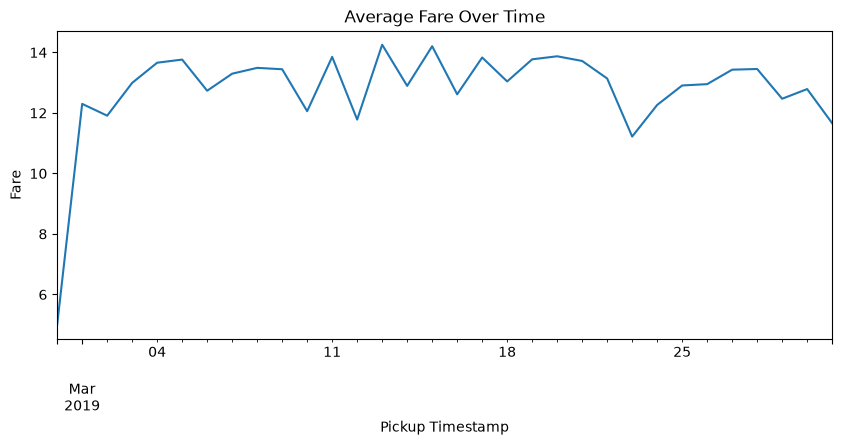

In [39]:
# Line chart
plt.figure(figsize=(10, 4))
df.set_index('pickup')['fare'].resample('D').mean().plot()
plt.title('Average Fare Over Time')
plt.xlabel('Pickup Timestamp')
plt.ylabel('Fare')
plt.show()

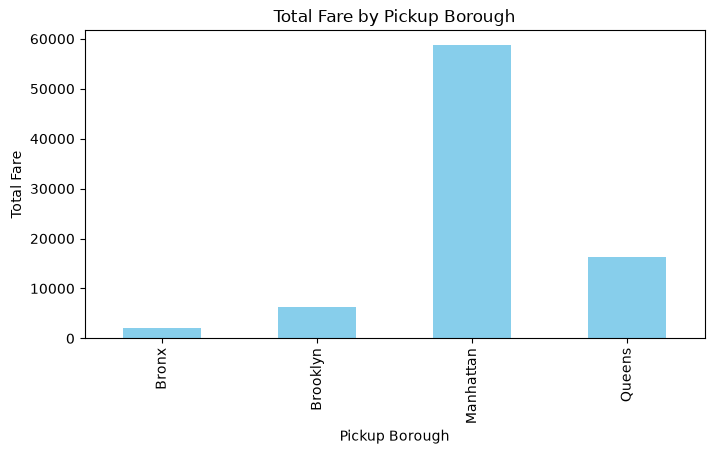

In [19]:
# Bar chart
plt.figure(figsize=(8, 4))
df.groupby('pickup_borough')['fare'].sum().plot(kind='bar', color='skyblue')
plt.title('Total Fare by Pickup Borough')
plt.xlabel('Pickup Borough')
plt.ylabel('Total Fare')
plt.show()

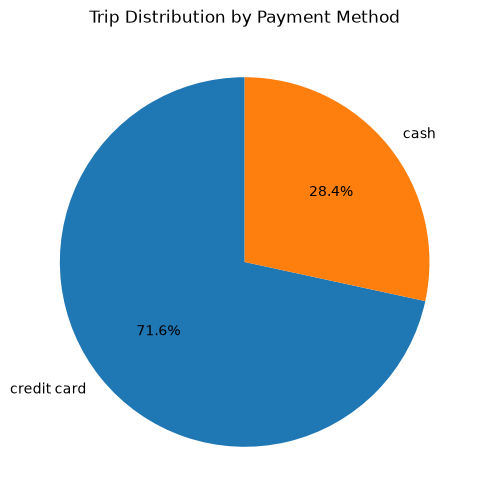

In [20]:
# Pie chart
plt.figure(figsize=(6, 6))
df['payment'].value_counts().plot(kind='pie', autopct='%1.1f%%', startangle=90)
plt.title('Trip Distribution by Payment Method')
plt.ylabel('')
plt.show()

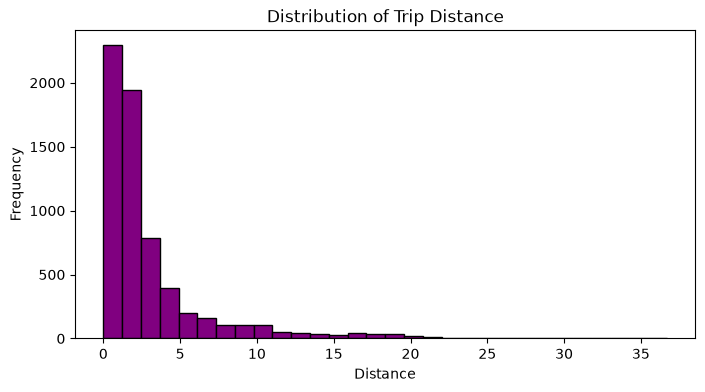

In [21]:
# Histogram
plt.figure(figsize=(8, 4))
plt.hist(df['distance'], bins=30, color='purple', edgecolor='black')
plt.title('Distribution of Trip Distance')
plt.xlabel('Distance')
plt.ylabel('Frequency')
plt.show()

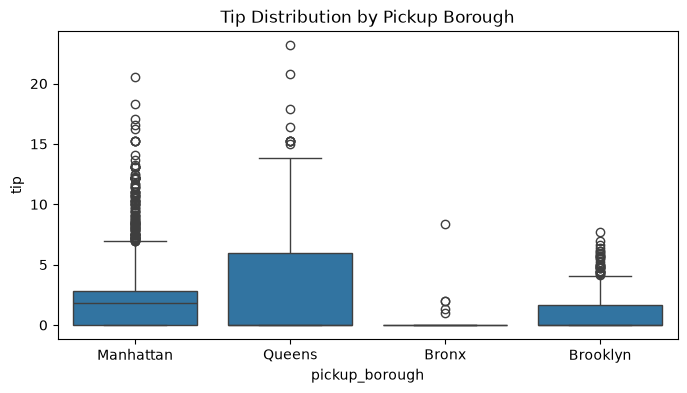

In [37]:
# Box plot
plt.figure(figsize=(8, 4))
sns.boxplot(x='pickup_borough', y='tip', data=df)
plt.title('Tip Distribution by Pickup Borough')
plt.show()

# visualizations using seaborn

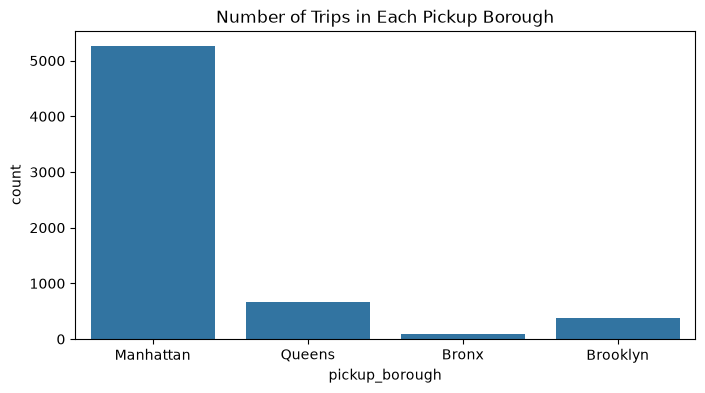

In [31]:
# count plot
plt.figure(figsize=(8, 4))
sns.countplot(x='pickup_borough', data=df)
plt.title('Number of Trips in Each Pickup Borough')
plt.show()

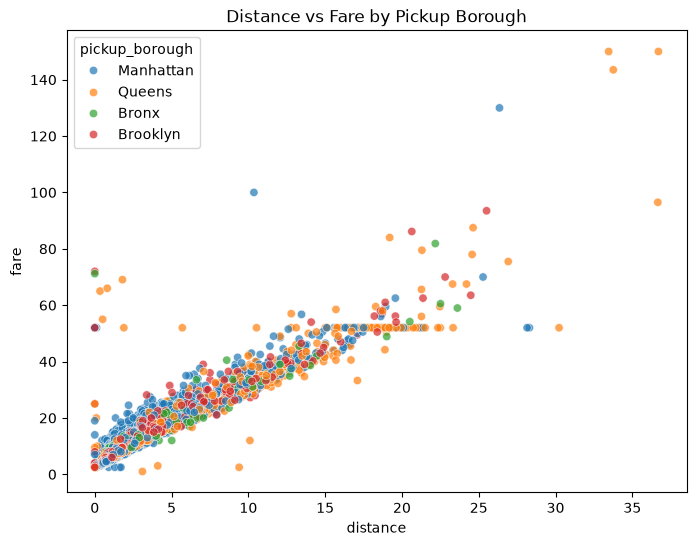

In [32]:
# scatter plot
plt.figure(figsize=(8, 6))
sns.scatterplot(x='distance', y='fare', hue='pickup_borough', data=df, alpha=0.7)
plt.title('Distance vs Fare by Pickup Borough')
plt.show()

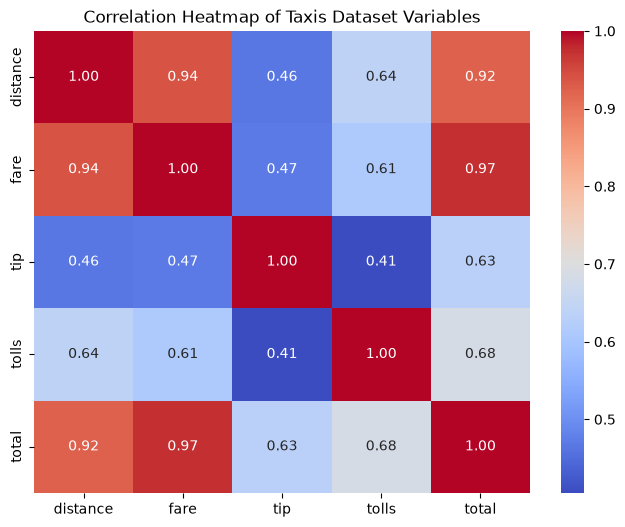

In [33]:
# Heat map
plt.figure(figsize=(8, 6))
numeric_cols = ['distance', 'fare', 'tip', 'tolls', 'total']
corr_matrix = df[numeric_cols].corr()
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Heatmap of Taxis Dataset Variables')
plt.show()

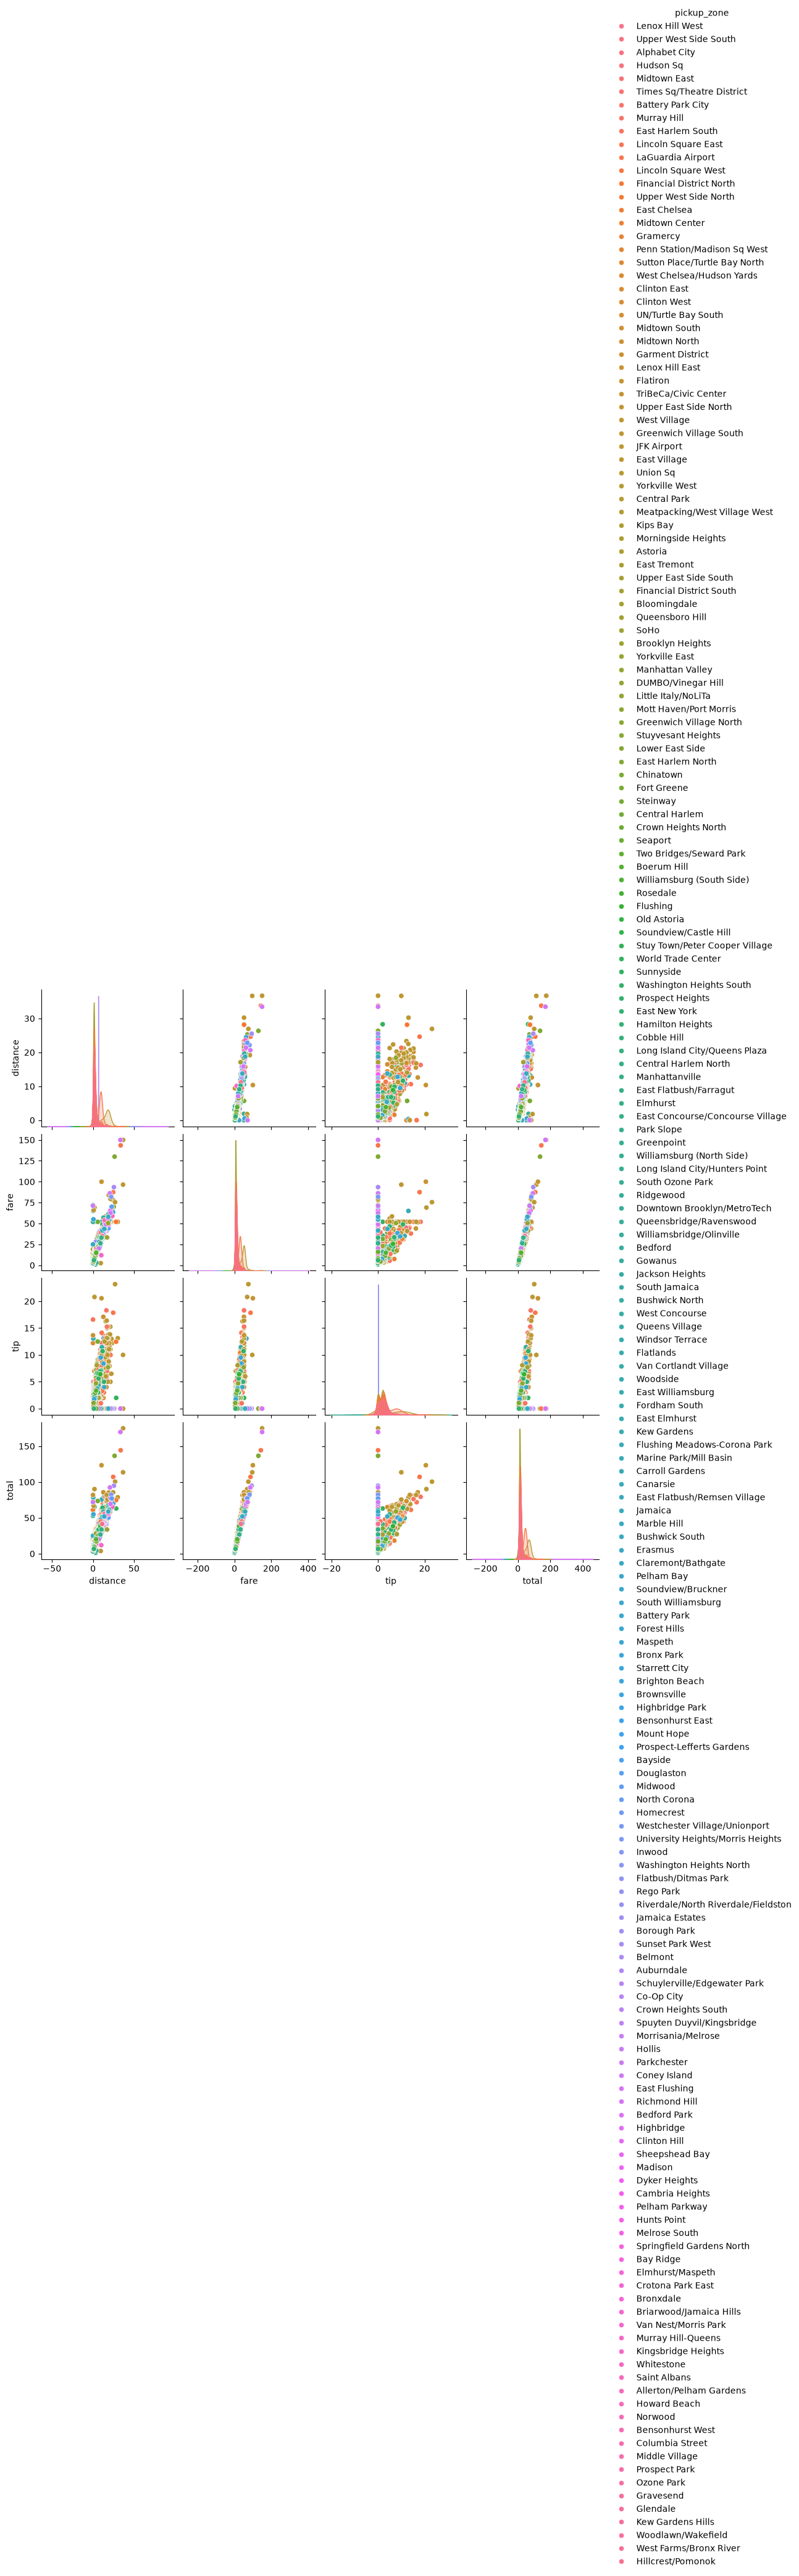

In [36]:
# pair plot
sns.pairplot(df[['distance', 'fare', 'tip', 'total', 'pickup_zone']].dropna(), hue='pickup_zone', height=2.5)
plt.show()

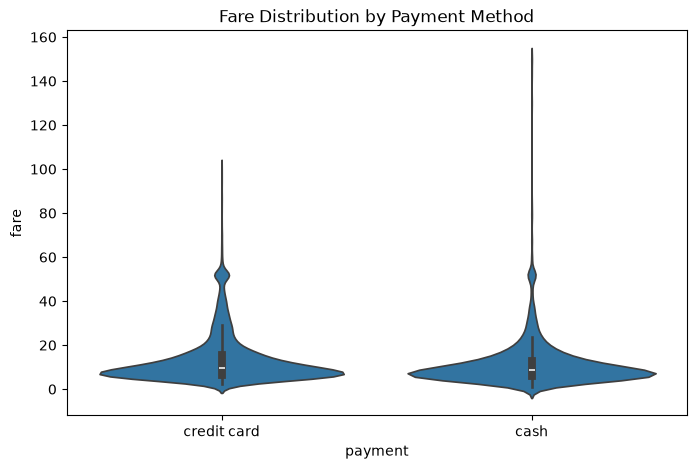

In [35]:
# violin plot
plt.figure(figsize=(8, 5))
sns.violinplot(x='payment', y='fare', data=df)
plt.title('Fare Distribution by Payment Method')
plt.show()